# Telco Customer Churn Prediction

Binary classification of telecom customers into "will churn" / "will stay" with tree-based models.

## Problem

Predict whether a customer will leave the company (churn) from their contract, services and billing data. Missing a real churner is more costly than a false alarm, so recall on the churn class is the key metric.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

## Data

IBM Telco Customer Churn dataset: 7,032 customers, 19 features (demographics, services, contract, charges) and the `Churn` label.

In [2]:
df = pd.read_csv('data/Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   str    
 1   gender            7032 non-null   str    
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   str    
 4   Dependents        7032 non-null   str    
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   str    
 7   MultipleLines     7032 non-null   str    
 8   InternetService   7032 non-null   str    
 9   OnlineSecurity    7032 non-null   str    
 10  OnlineBackup      7032 non-null   str    
 11  DeviceProtection  7032 non-null   str    
 12  TechSupport       7032 non-null   str    
 13  StreamingTV       7032 non-null   str    
 14  StreamingMovies   7032 non-null   str    
 15  Contract          7032 non-null   str    
 16  PaperlessBilling  7032 non-null   str    
 17  Paymen

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7032.0,0.162400,0.368844,0.00,0.0000,0.000,0.0000,1.00
tenure,7032.0,32.421786,24.545260,1.00,9.0000,29.000,55.0000,72.00
MonthlyCharges,7032.0,64.798208,30.085974,18.25,35.5875,70.350,89.8625,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.4500,1397.475,3794.7375,8684.80


In [5]:
df.isna().sum().sort_values(ascending=False)

customerID          0
DeviceProtection    0
TotalCharges        0
MonthlyCharges      0
PaymentMethod       0
PaperlessBilling    0
Contract            0
StreamingMovies     0
StreamingTV         0
TechSupport         0
OnlineBackup        0
gender              0
OnlineSecurity      0
InternetService     0
MultipleLines       0
PhoneService        0
tenure              0
Dependents          0
Partner             0
SeniorCitizen       0
Churn               0
dtype: int64

## EDA

There are no missing values. The classes are imbalanced: roughly a quarter of customers churned.

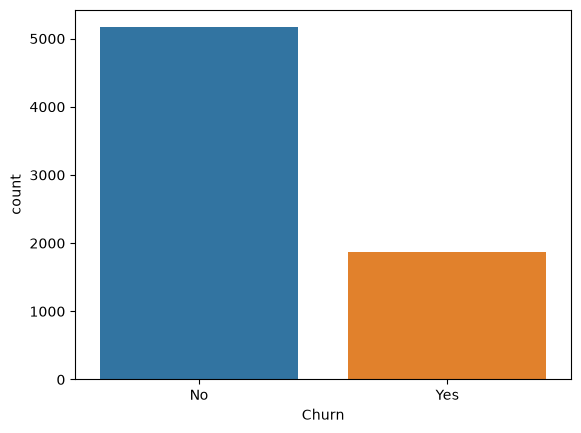

In [6]:
sns.countplot(df, x='Churn', hue='Churn');

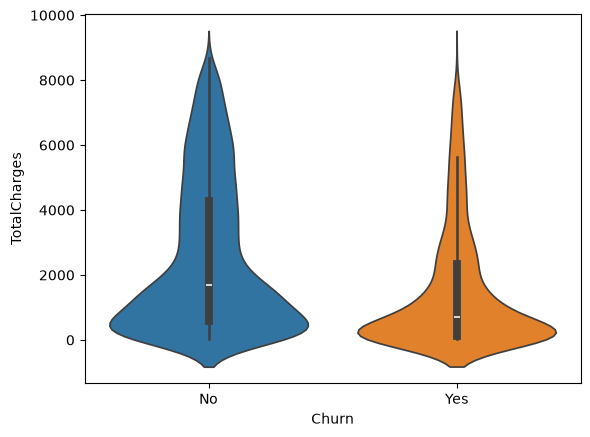

In [7]:
sns.violinplot(df, x='Churn', y='TotalCharges', hue='Churn');

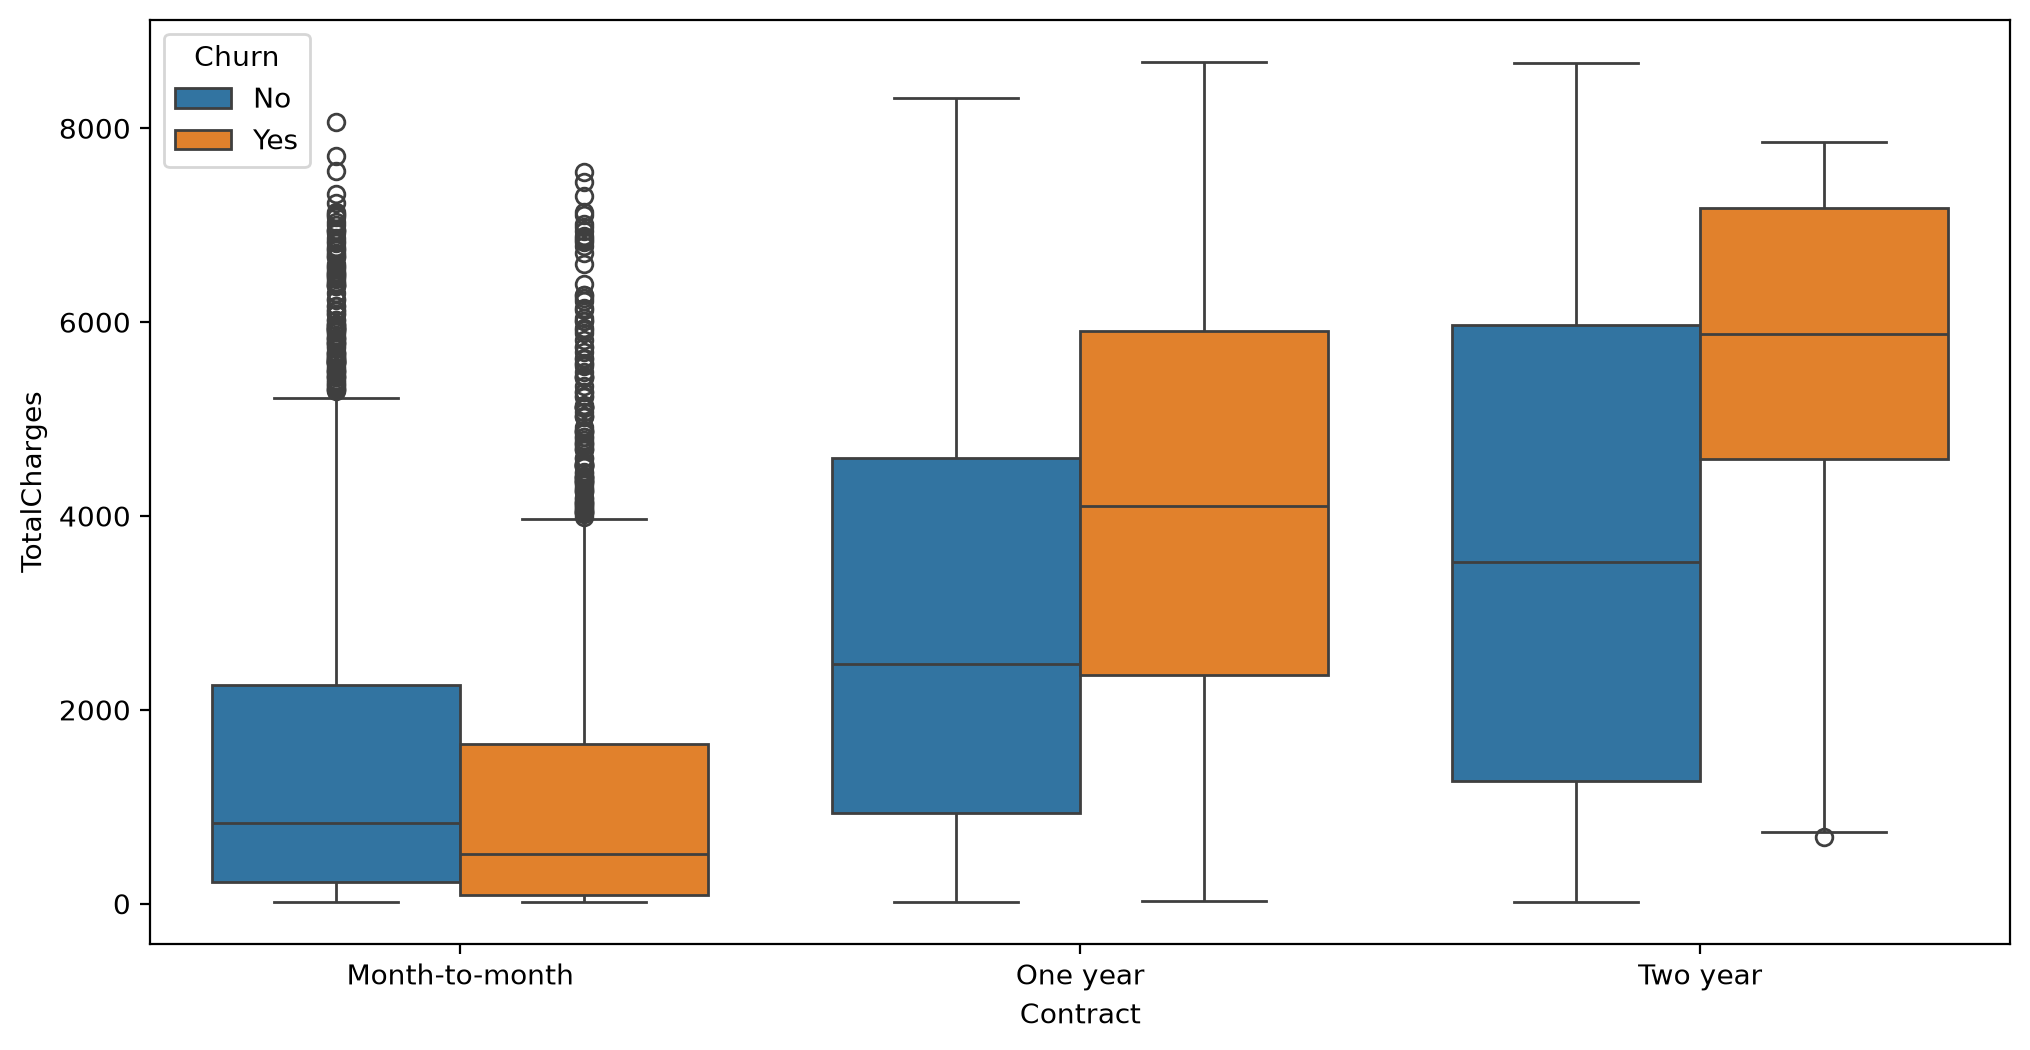

In [8]:
plt.figure(figsize=(12,6), dpi=200)
sns.boxplot(df, x='Contract', y='TotalCharges', hue='Churn');

In [9]:
pd.crosstab(df['Contract'], df['Churn'], normalize='index')

Churn,No,Yes
Contract,,
Month-to-month,0.572903,0.427097
One year,0.887228,0.112772
Two year,0.971513,0.028487


### Correlation of features with churn

Categorical features are one-hot encoded so that their correlation with `Churn_Yes` can be computed.

In [10]:
columns = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
           'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'InternetService',
           'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
columns.append('Churn')
df_dummies = pd.get_dummies(data=df, columns=columns)

In [11]:
corr = df_dummies.corr(numeric_only=True)
corr = corr['Churn_Yes'].drop(['Churn_No', 'Churn_Yes'])
corr = corr.sort_values()

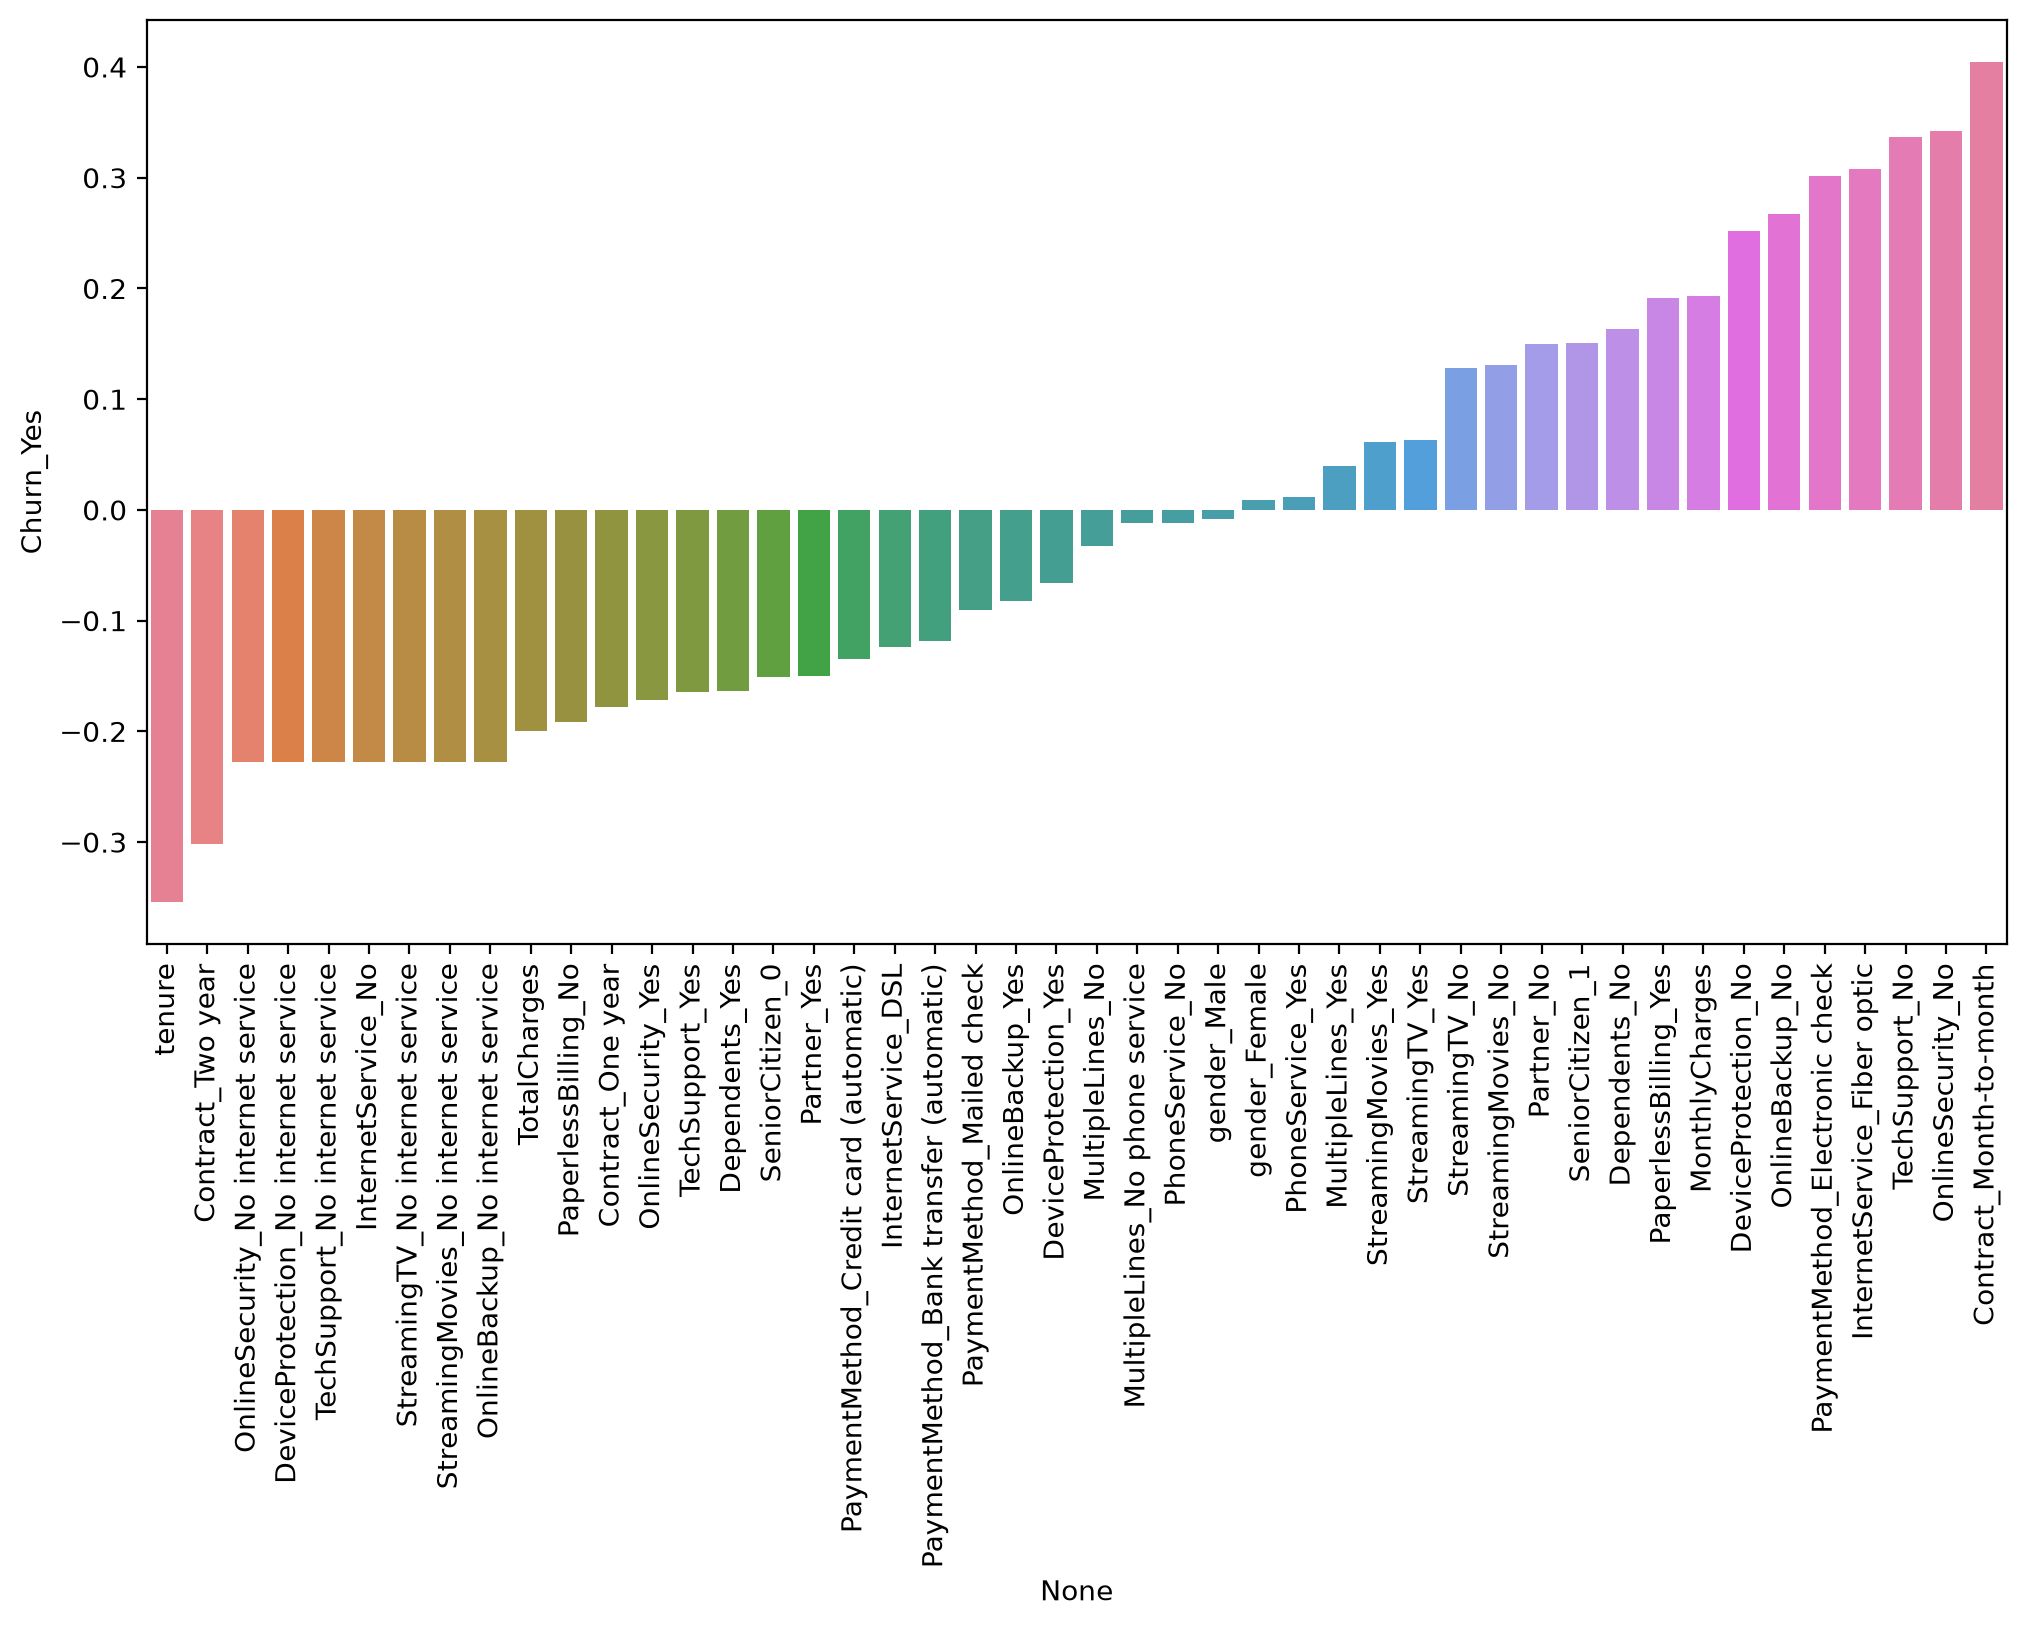

In [12]:
plt.figure(figsize=(12,6), dpi=200)
sns.barplot(x=corr.index, y=corr, hue=corr.index)
plt.xticks(rotation=90)
plt.savefig('images/churn_correlations.png', bbox_inches='tight');

### Churn by tenure and contract

`tenure` is the number of months a person has been a customer.

In [13]:
df['Contract'].unique()

<StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

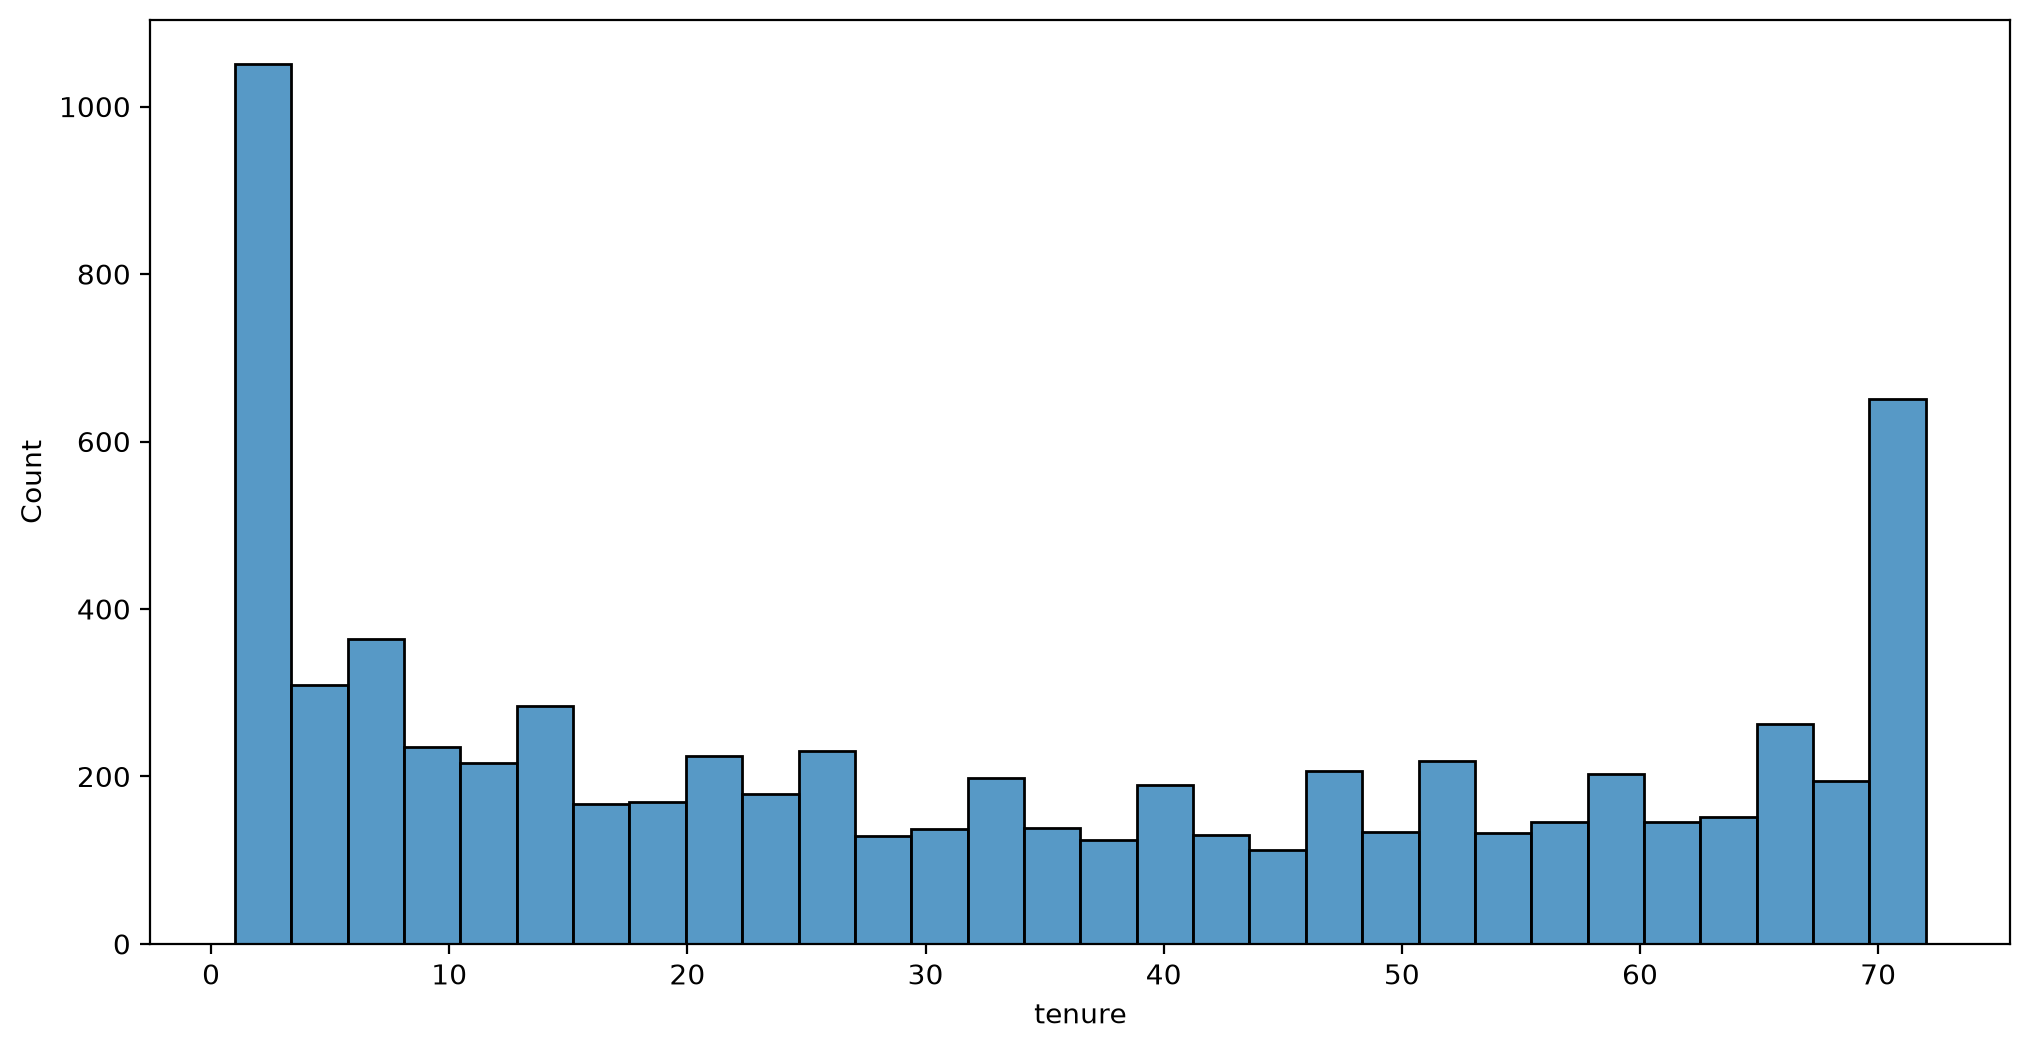

In [14]:
plt.figure(figsize=(12,6), dpi=200)
sns.histplot(df, x='tenure', bins=30);

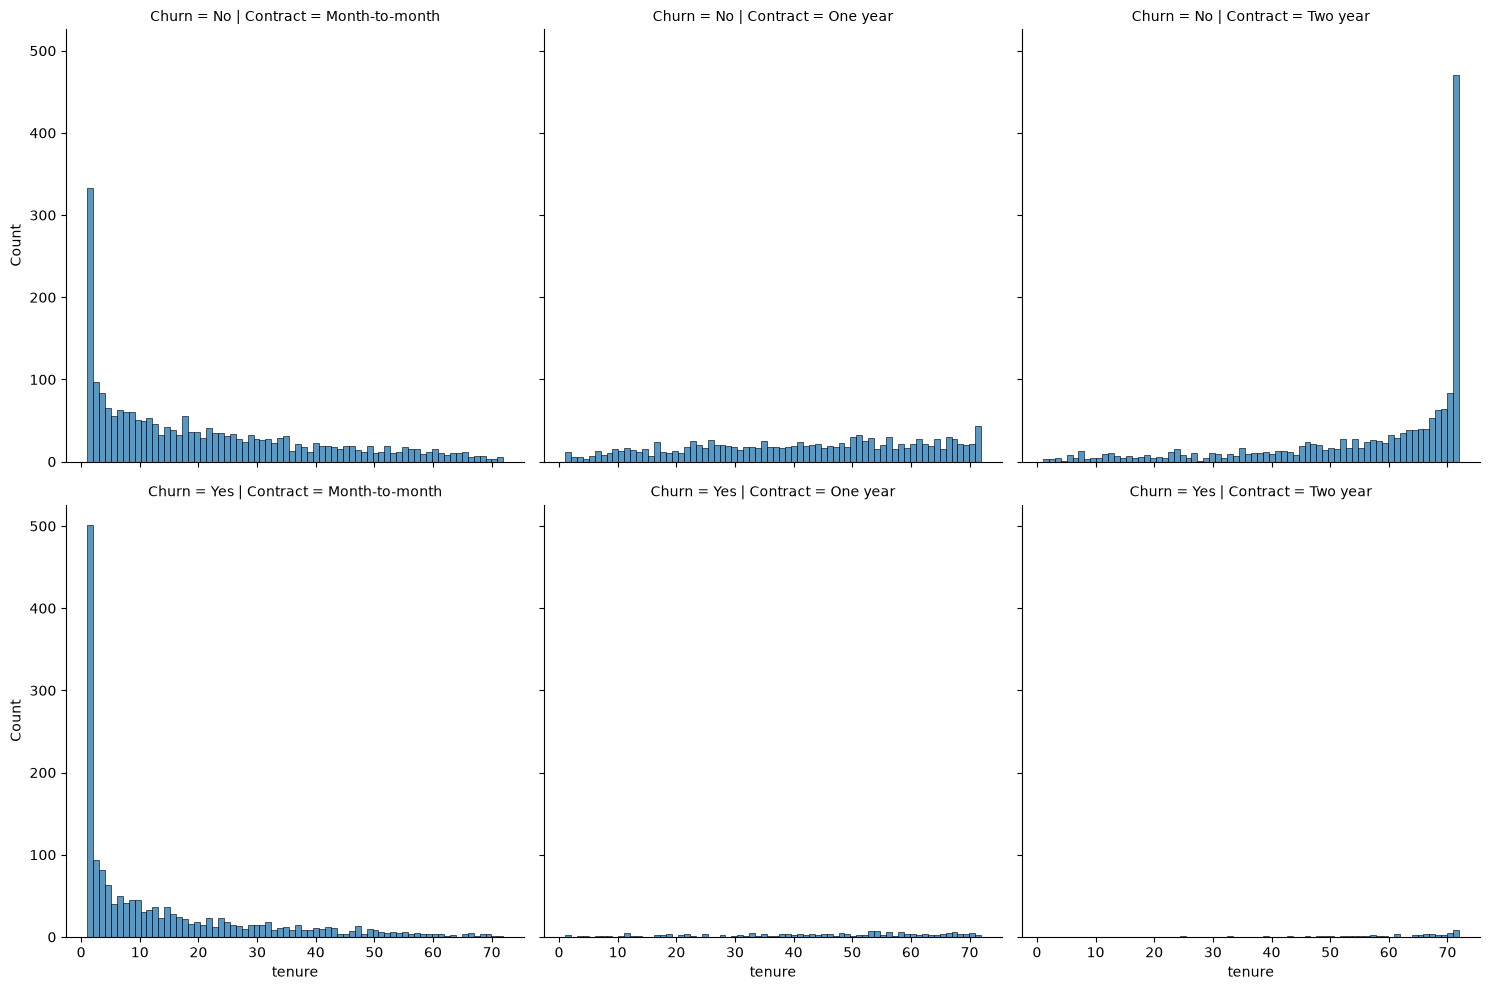

In [15]:
sns.displot(df, x='tenure', row='Churn', col='Contract', bins=70);

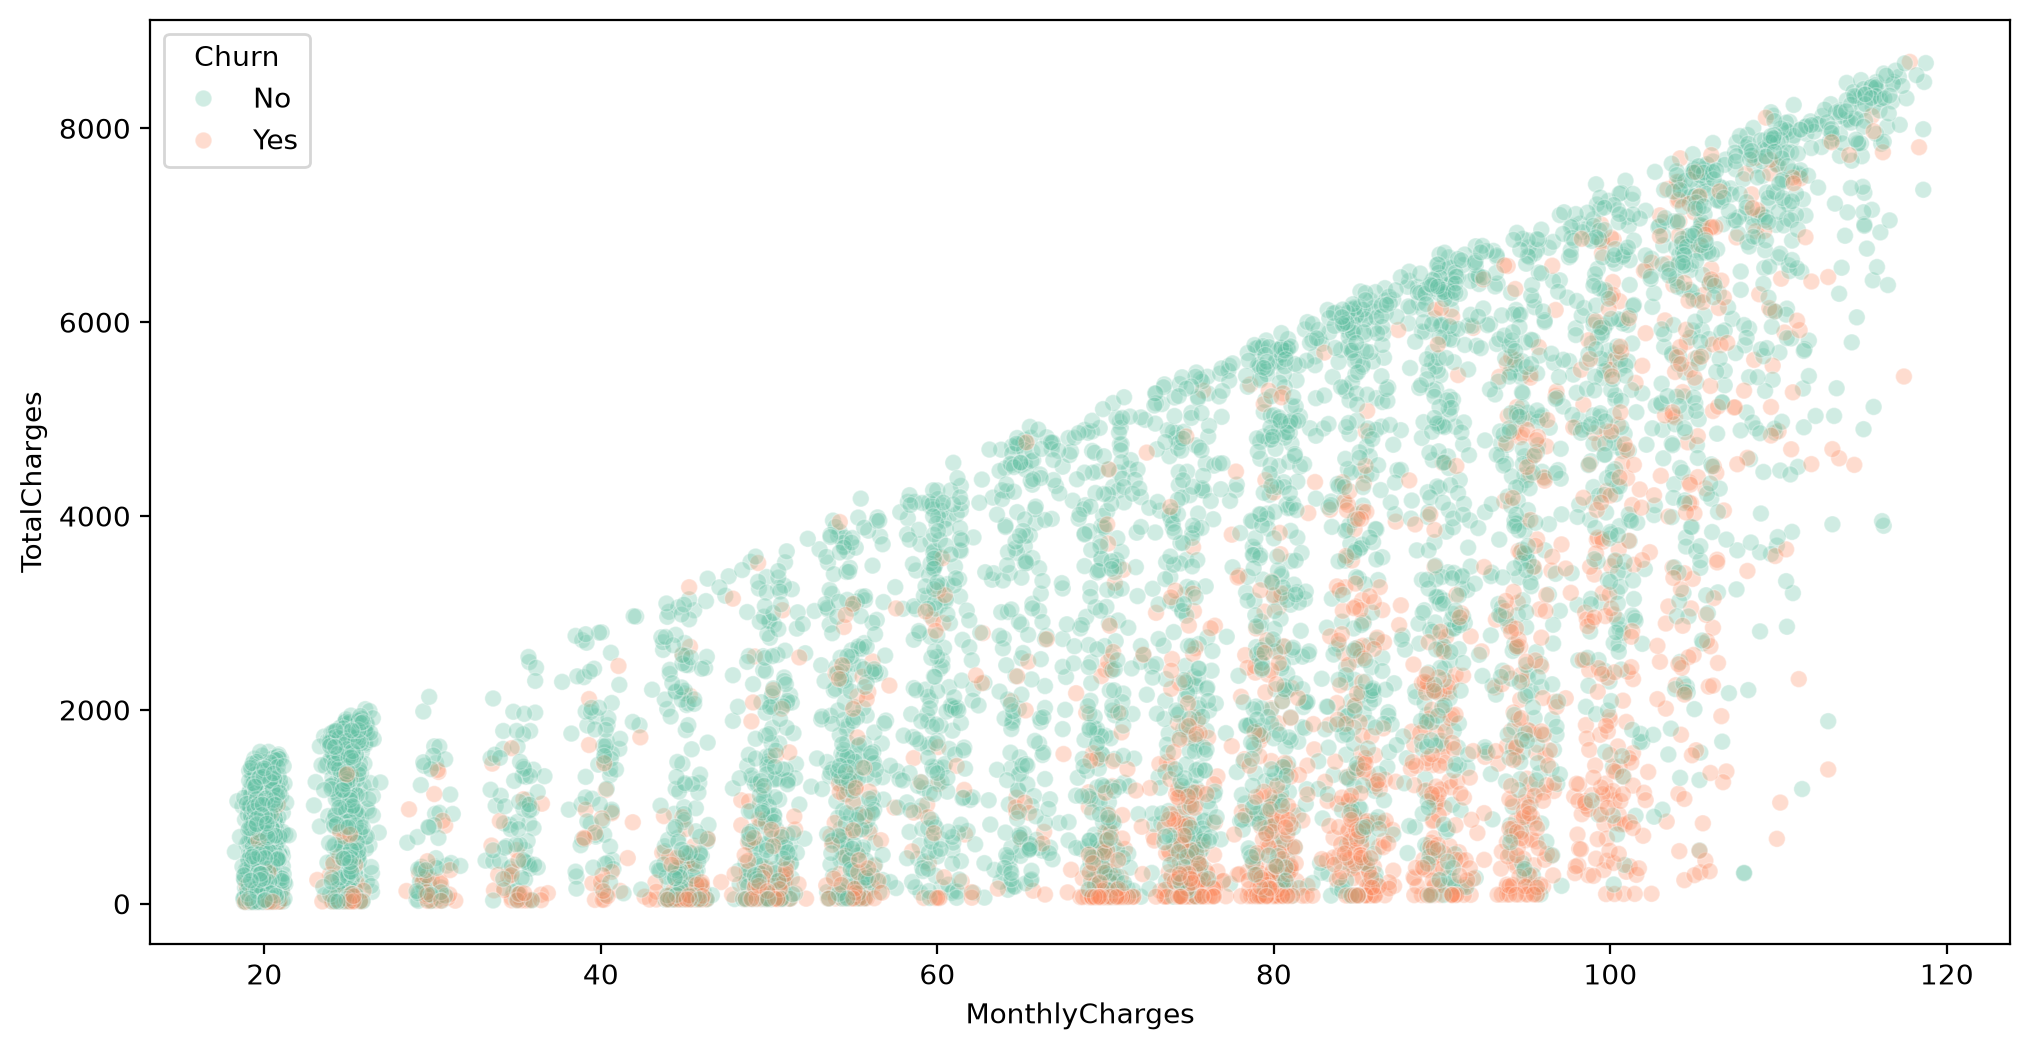

In [16]:
plt.figure(figsize=(12,6), dpi=200)
sns.scatterplot(df, x='MonthlyCharges', y='TotalCharges', hue='Churn', palette='Set2', alpha=0.3);

Churn rate (%) for every tenure value, treating each month as a cohort.

In [17]:
churn_percentages = pd.crosstab(df['tenure'], df['Churn'], normalize='index') * 100
churn_percentages

Churn,No,Yes
tenure,,
1,38.009788,61.990212
2,48.319328,51.680672
3,53.000000,47.000000
4,52.840909,47.159091
5,51.879699,48.120301
...,...,...
68,91.000000,9.000000
69,91.578947,8.421053
70,90.756303,9.243697


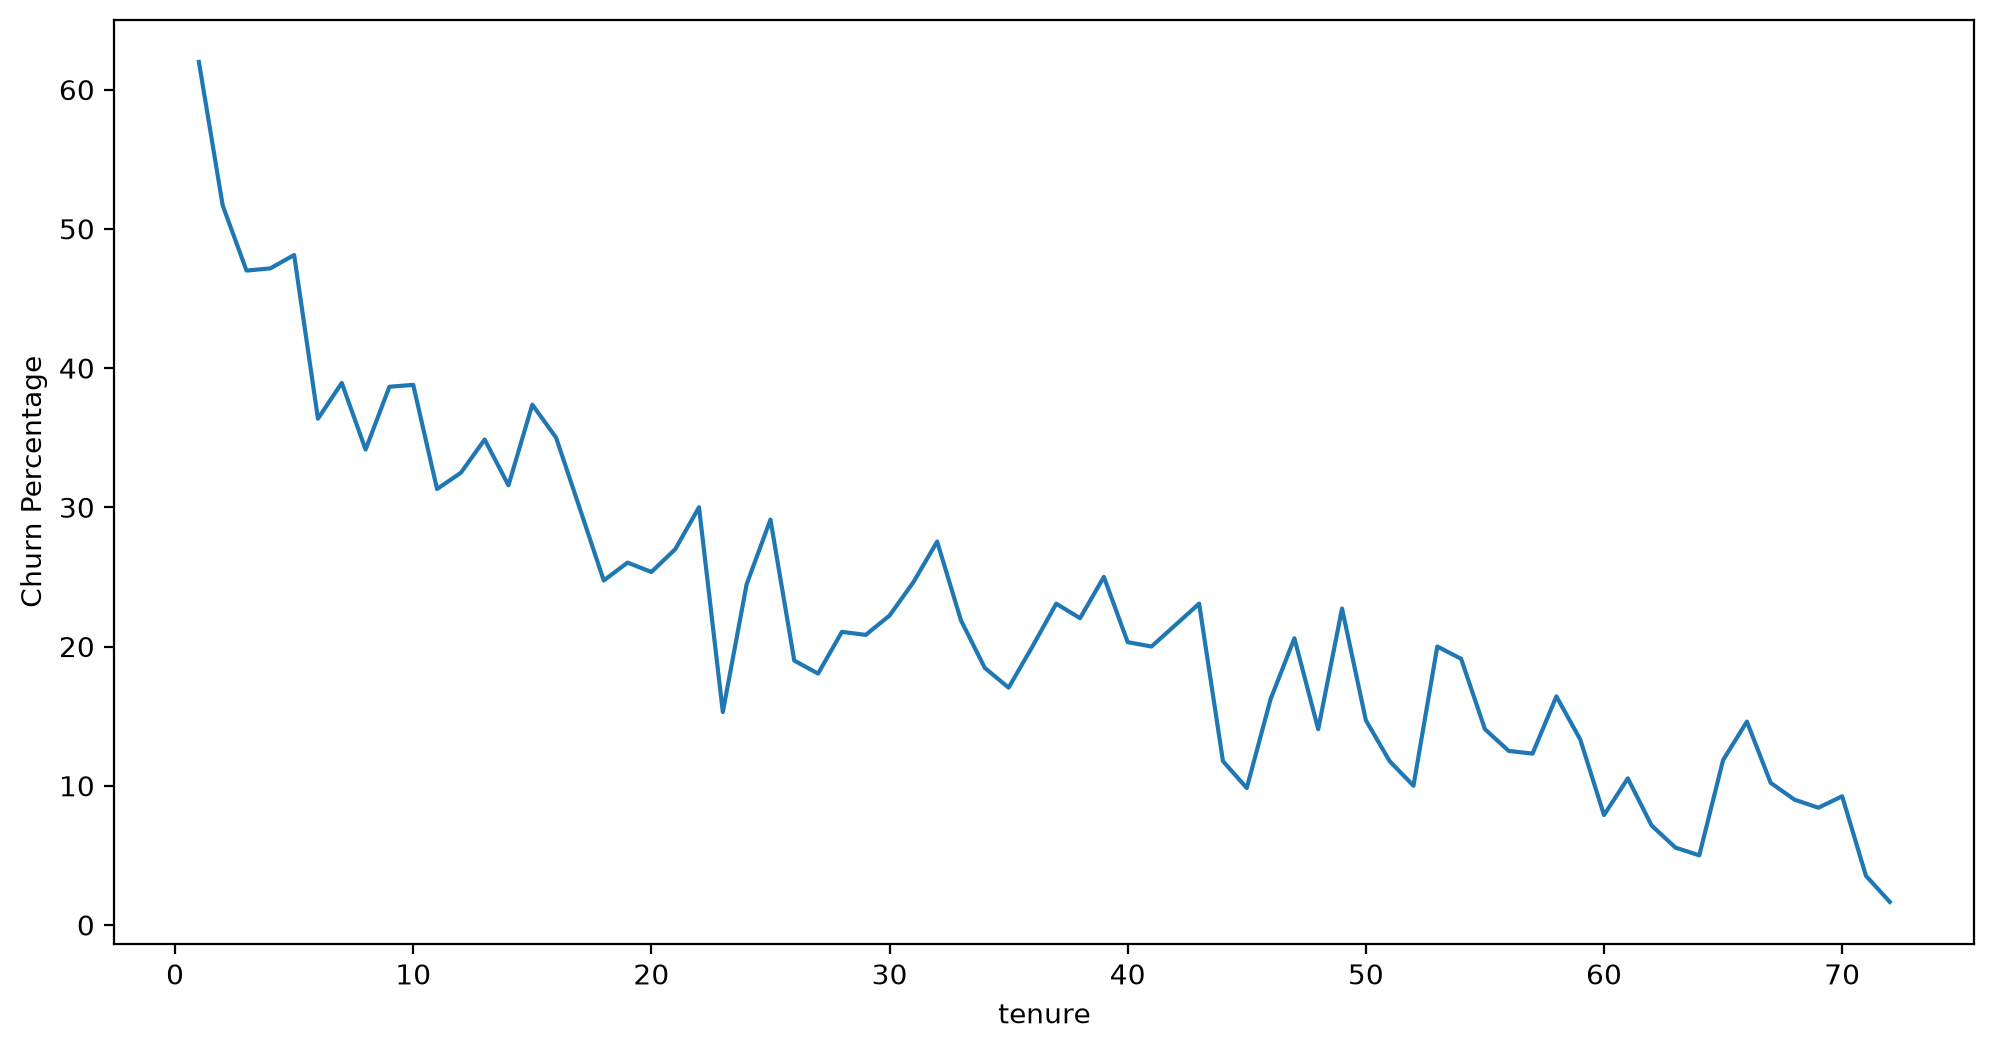

In [18]:
plt.figure(figsize=(12,6), dpi=200)
plt.plot(churn_percentages.index, churn_percentages['Yes'])
plt.xlabel('tenure')
plt.ylabel('Churn Percentage')
plt.savefig('images/churn_by_tenure.png', bbox_inches='tight');

Larger cohorts: tenure grouped into four bins.

In [19]:
def tenure_cohort(tenure) -> str:
    if 0 <= tenure <= 12:
        return '0 - 12 Months'
    elif 12 < tenure <= 24:
        return '12 - 24 Months'
    elif 24 < tenure <= 48:
        return '24 - 48 Months'
    else:
        return 'Over 48 Months'

In [20]:
df['Tenure Cohort'] = df['tenure'].apply(tenure_cohort)
df[['tenure', 'Tenure Cohort']].head()

,tenure,Tenure Cohort
0,1,0 - 12 Months
1,34,24 - 48 Months
2,2,0 - 12 Months
3,45,24 - 48 Months
4,2,0 - 12 Months


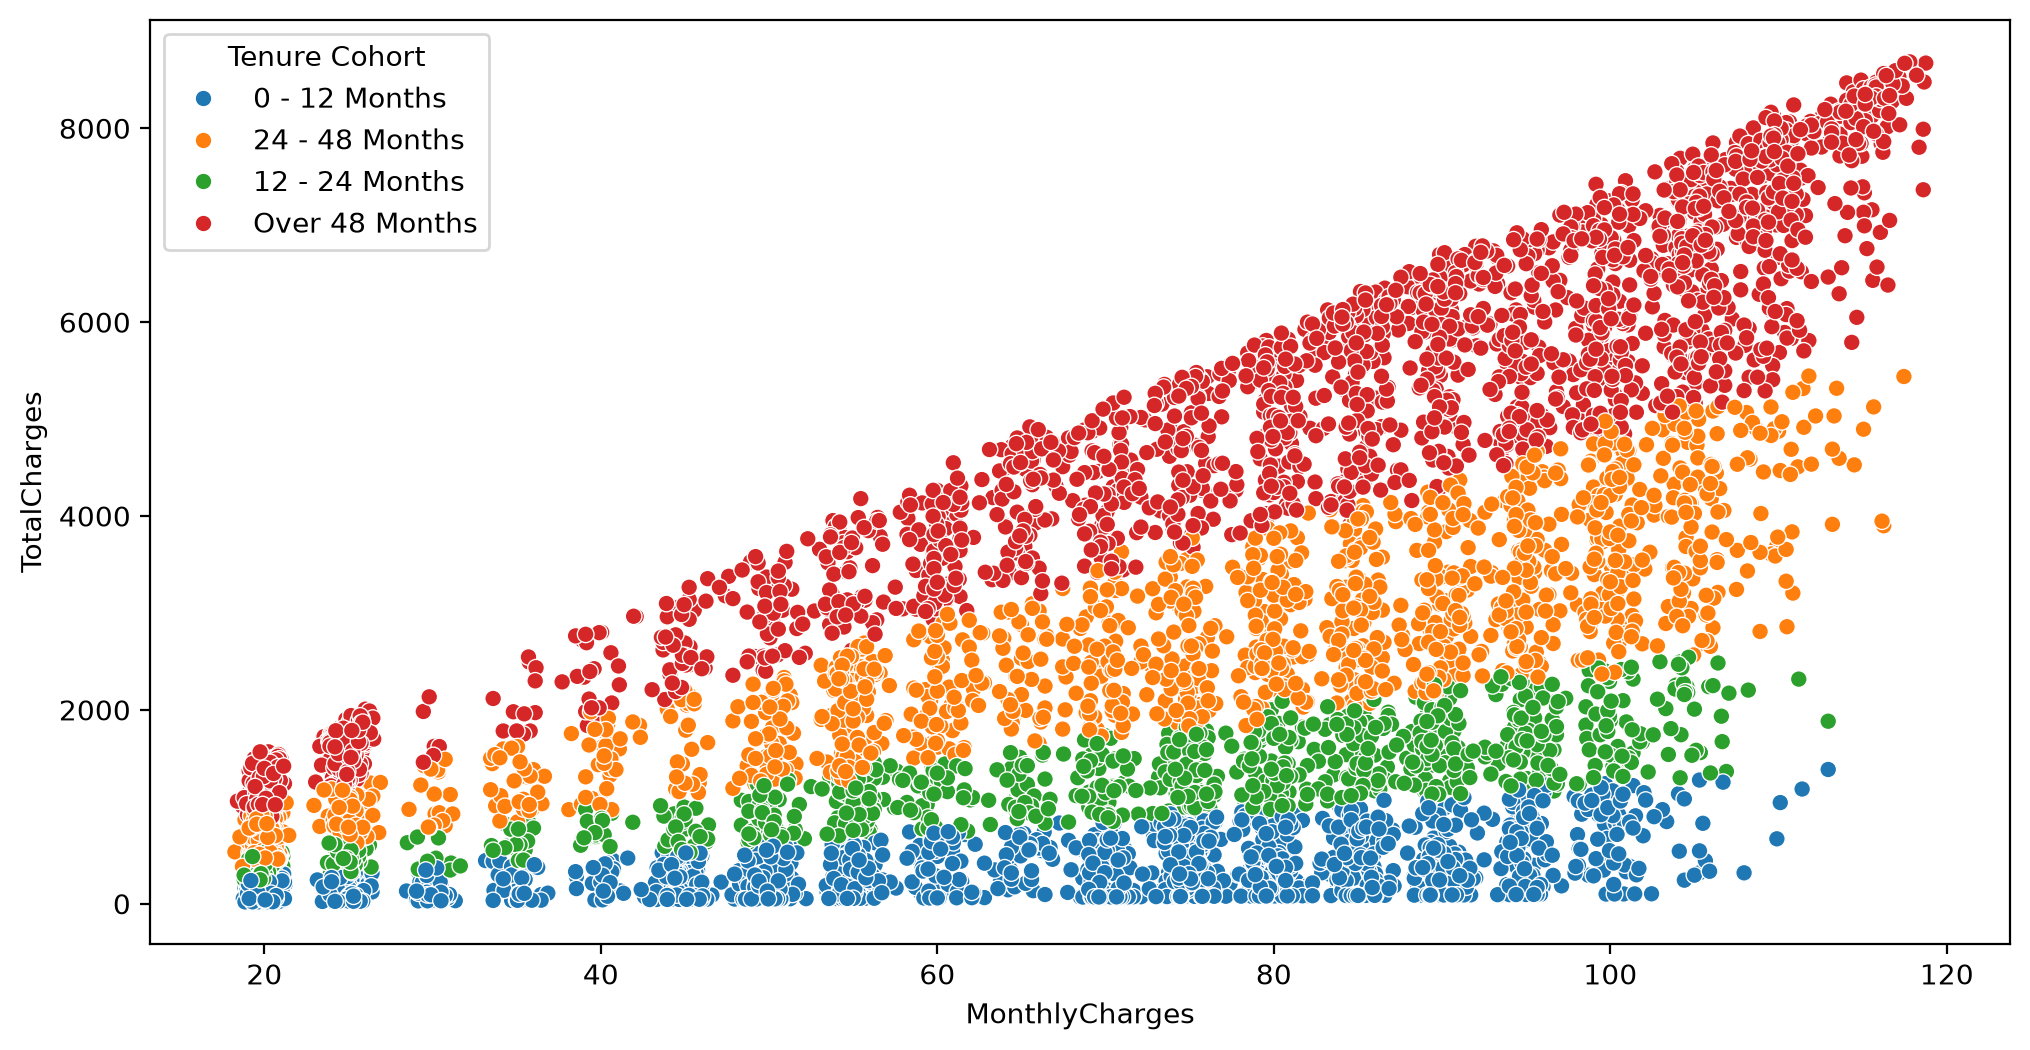

In [21]:
plt.figure(figsize=(12,6), dpi=200)
sns.scatterplot(df, x='MonthlyCharges', y='TotalCharges', hue='Tenure Cohort');

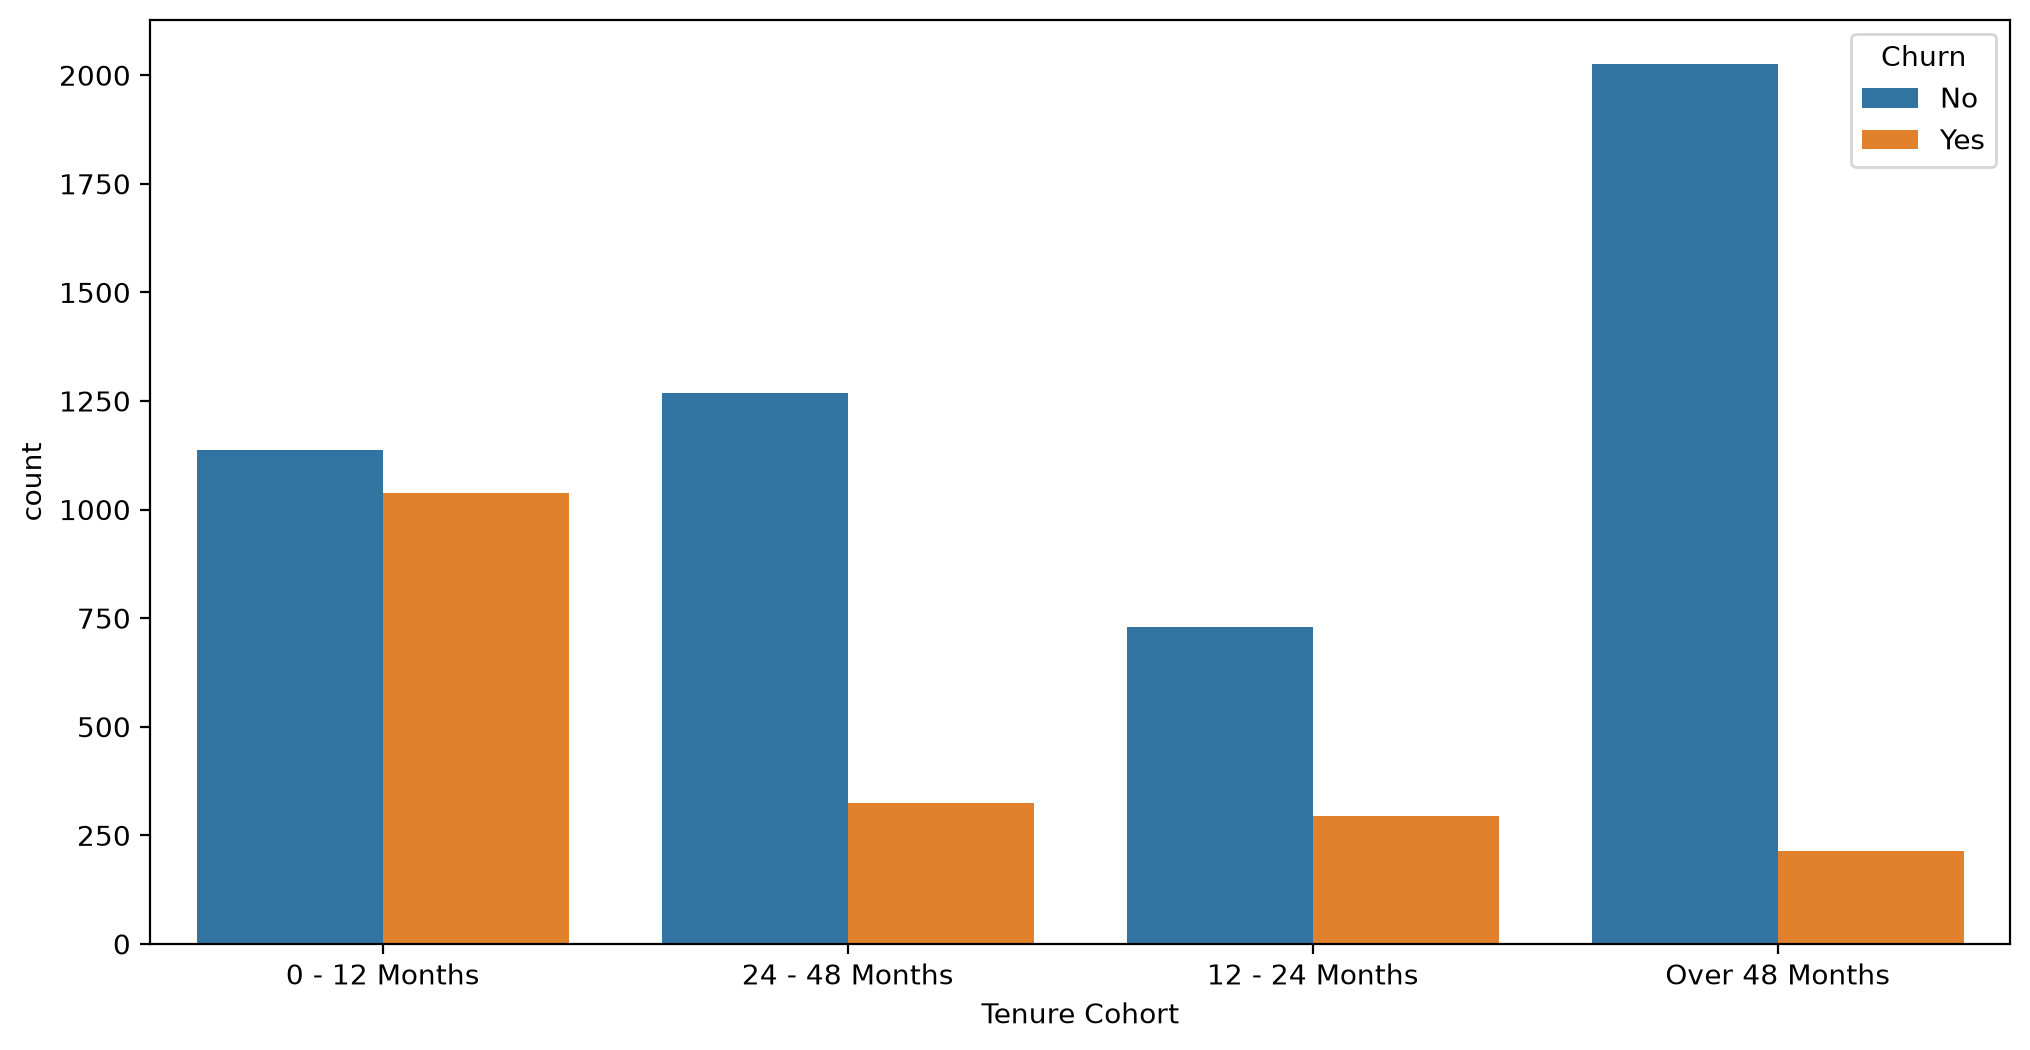

In [22]:
plt.figure(figsize=(12,6), dpi=200)
sns.countplot(df, x='Tenure Cohort', hue='Churn');

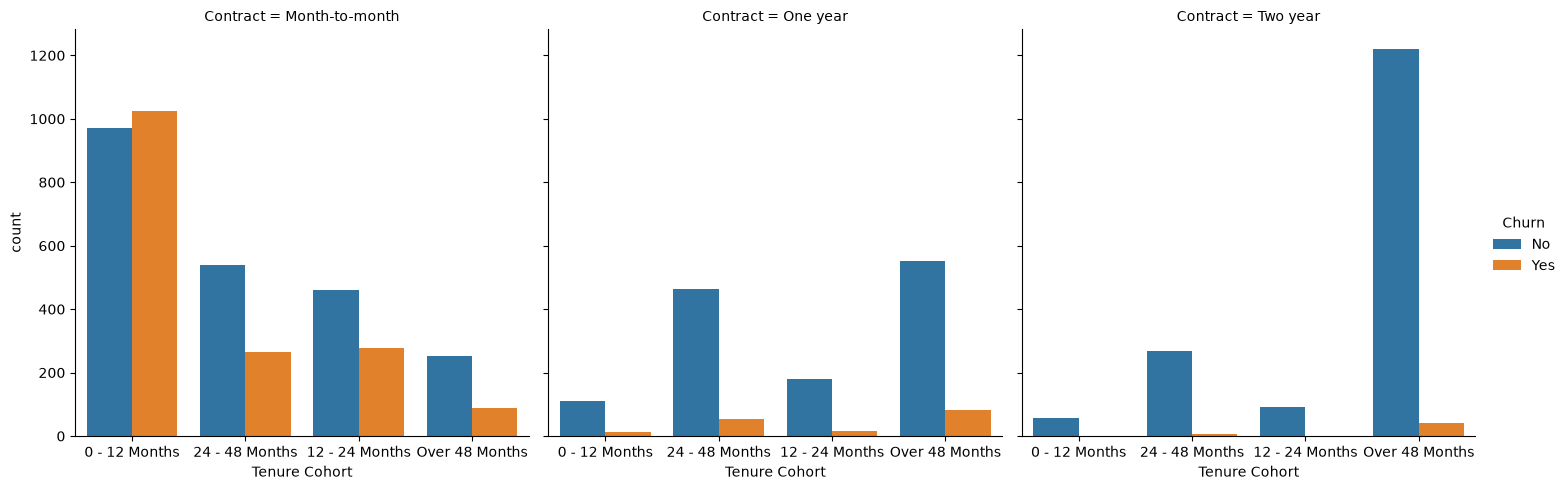

In [23]:
sns.catplot(df, x='Tenure Cohort', col='Contract', hue='Churn', kind='count');

## Preprocessing

`customerID` is a unique identifier and `Tenure Cohort` duplicates `tenure`, so both are dropped. Categorical features are one-hot encoded and 10% of the data is held out for testing.

In [24]:
X = df.drop(['Churn', 'customerID', 'Tenure Cohort'], axis=1)
y = df['Churn'].map({'Yes': 1, 'No': 0})
X = pd.get_dummies(X, drop_first=True)
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=101)

## Modeling

Four tree-based models, each tuned with 5-fold `GridSearchCV` optimizing F1 for the churn class and evaluated on the test set.

### Decision Tree

In [26]:
tree_model = DecisionTreeClassifier(random_state=101)
params = {
    'max_depth': [3, 5, 7, 10, 15, 30, None],
    'class_weight': [None, 'balanced'],
    'min_samples_leaf': [1, 5, 10, 20, 30]
}
grid_tree = GridSearchCV(tree_model, param_grid=params, scoring='f1')
grid_tree.fit(X_train, y_train)
grid_tree.best_params_

{'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 30}

In [27]:
tree_preds = grid_tree.predict(X_test)
print(classification_report(y_test, tree_preds))

              precision    recall  f1-score   support

           0       0.93      0.71      0.80       557
           1       0.42      0.78      0.54       147

    accuracy                           0.73       704
   macro avg       0.67      0.75      0.67       704
weighted avg       0.82      0.73      0.75       704



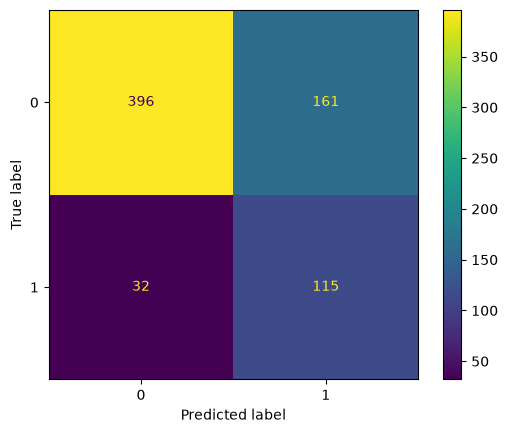

In [28]:
ConfusionMatrixDisplay.from_predictions(y_test, tree_preds);

In [29]:
imp_feat = pd.DataFrame(index=X.columns, data=grid_tree.best_estimator_.feature_importances_, columns=['Importance'])
(imp_feat.sort_values('Importance', ascending=False) * 100).round(2)

,Importance
Contract_Two year,40.45
Contract_One year,25.97
InternetService_Fiber optic,10.68
tenure,10.42
StreamingMovies_Yes,3.00
MonthlyCharges,2.97
PaymentMethod_Electronic check,2.17
TechSupport_No internet service,1.65
TotalCharges,1.40
MultipleLines_No phone service,1.23


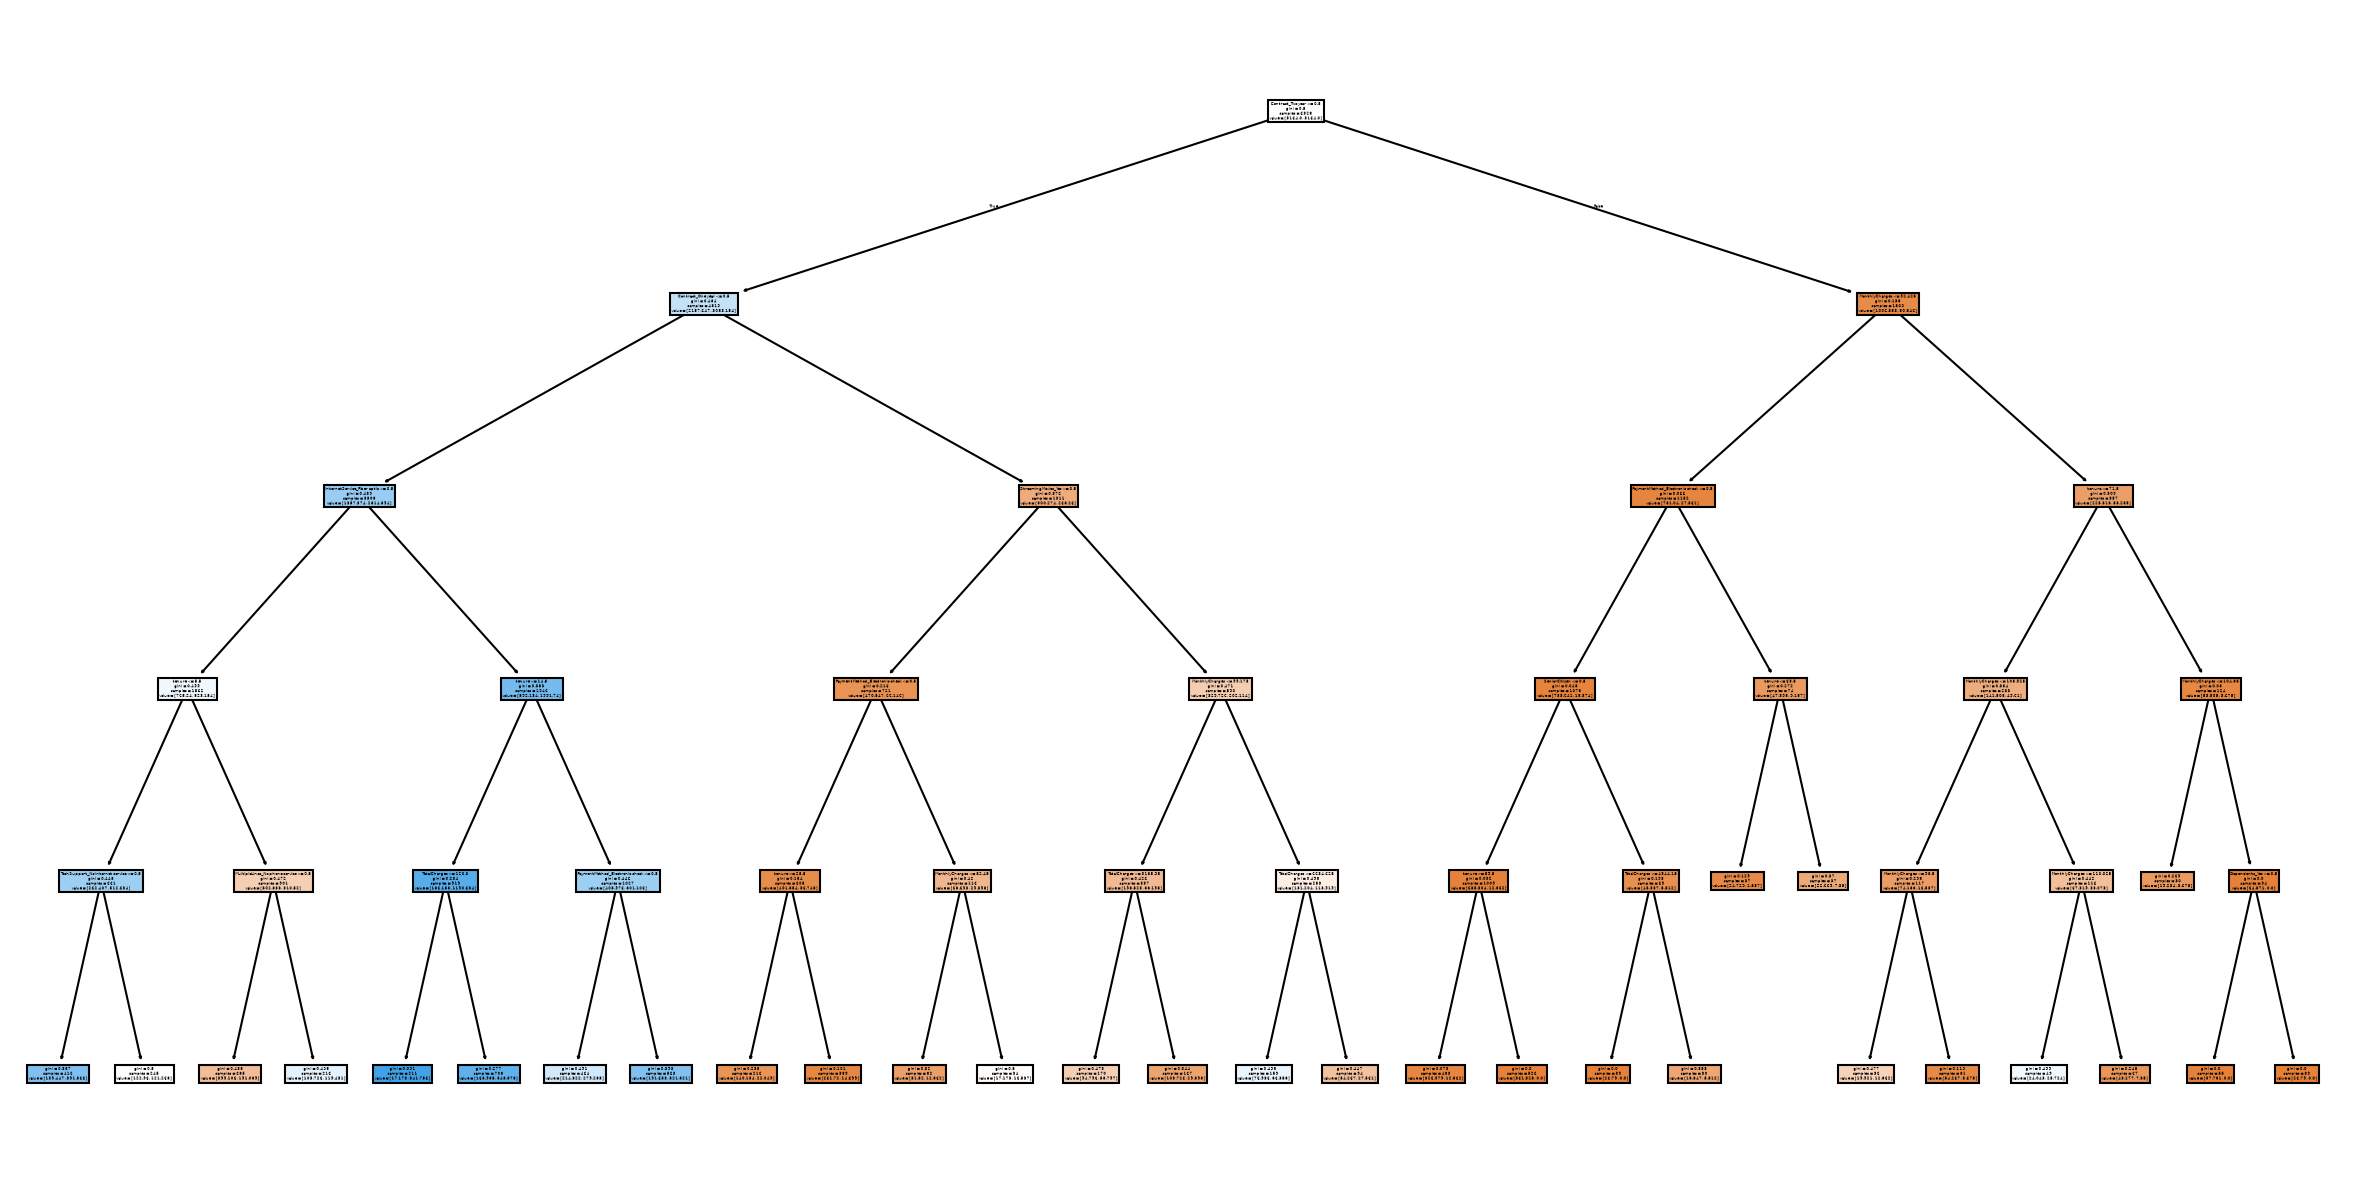

In [30]:
plt.figure(figsize=(20,10), dpi=150)
plot_tree(grid_tree.best_estimator_, feature_names=X.columns, filled=True);

### Random Forest

In [31]:
rnd_forest = RandomForestClassifier(random_state=101, n_jobs=-1)
params = {
    'n_estimators': [64, 100, 128, 200],
    'max_features': ['sqrt', 'log2', None],
    'min_samples_leaf': [1, 5, 10],
    'class_weight': [None, 'balanced']
}
grid_forest = GridSearchCV(rnd_forest, param_grid=params, scoring='f1')
grid_forest.fit(X_train, y_train)
grid_forest.best_params_

{'class_weight': 'balanced',
 'max_features': 'log2',
 'min_samples_leaf': 5,
 'n_estimators': 100}

In [32]:
forest_preds = grid_forest.predict(X_test)
print(classification_report(y_test, forest_preds))

              precision    recall  f1-score   support

           0       0.91      0.75      0.83       557
           1       0.44      0.72      0.54       147

    accuracy                           0.75       704
   macro avg       0.67      0.74      0.68       704
weighted avg       0.81      0.75      0.77       704



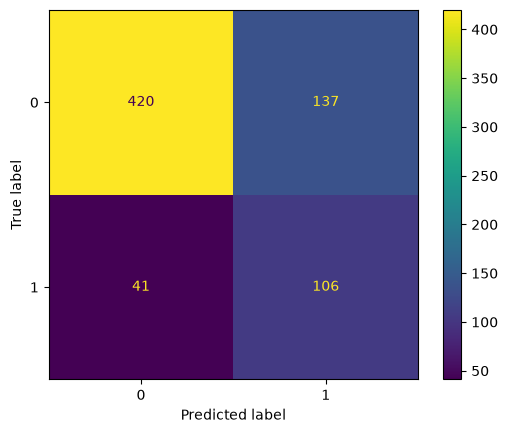

In [33]:
ConfusionMatrixDisplay.from_predictions(y_test, forest_preds);

### AdaBoost

In [34]:
ada_model = AdaBoostClassifier(random_state=101)
params = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.5, 1],
}
grid_ada = GridSearchCV(ada_model, param_grid=params, scoring='f1')
grid_ada.fit(X_train, y_train)
grid_ada.best_params_

{'learning_rate': 1, 'n_estimators': 200}

In [35]:
ada_preds = grid_ada.predict(X_test)
print(classification_report(y_test, ada_preds))

              precision    recall  f1-score   support

           0       0.88      0.92      0.90       557
           1       0.62      0.50      0.55       147

    accuracy                           0.83       704
   macro avg       0.75      0.71      0.73       704
weighted avg       0.82      0.83      0.82       704



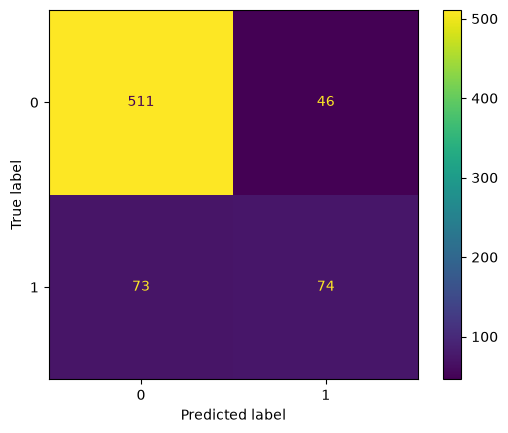

In [36]:
ConfusionMatrixDisplay.from_predictions(y_test, ada_preds);

### Gradient Boosting

In [37]:
gradient_model = GradientBoostingClassifier(random_state=101)
params = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5],
}
grid_gr = GridSearchCV(gradient_model, param_grid=params, scoring='f1')
grid_gr.fit(X_train, y_train)
grid_gr.best_params_

{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}

In [38]:
gr_preds = grid_gr.predict(X_test)
print(classification_report(y_test, gr_preds))

              precision    recall  f1-score   support

           0       0.87      0.90      0.89       557
           1       0.57      0.49      0.53       147

    accuracy                           0.82       704
   macro avg       0.72      0.70      0.71       704
weighted avg       0.81      0.82      0.81       704



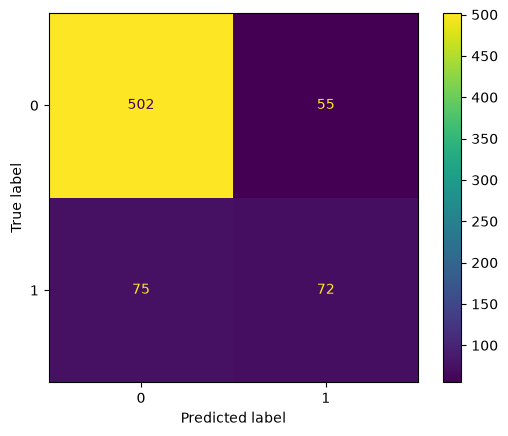

In [39]:
ConfusionMatrixDisplay.from_predictions(y_test, gr_preds);

## Results

Precision, recall and F1 for the churn class (1) on the test set.

In [40]:
model_preds = {
    'Decision Tree': tree_preds,
    'Random Forest': forest_preds,
    'AdaBoost': ada_preds,
    'Gradient Boosting': gr_preds,
}
results = {name: classification_report(y_test, preds, output_dict=True)['1']
           for name, preds in model_preds.items()}
results = pd.DataFrame(results).T[['precision', 'recall', 'f1-score']].round(2)
results

,precision,recall,f1-score
Decision Tree,0.42,0.78,0.54
Random Forest,0.44,0.72,0.54
AdaBoost,0.62,0.50,0.55
Gradient Boosting,0.57,0.49,0.53


## Conclusions

All four models were tuned with grid search and reach almost the same F1 on the churn class (0.53-0.55), so F1 alone does not separate them. The difference is in the precision/recall trade-off: the models with `class_weight='balanced'` (Decision Tree, Random Forest) find far more churners, while the boosting models are more precise but miss about half of them.

For the business I would pick the **Decision Tree**: it has the highest recall (0.78), catching 115 of 147 churners in the test set versus 74 for AdaBoost. Missing a churner means losing the customer, while a false alarm only costs a retention offer, so the extra false alarms (precision 0.42) are acceptable. The tree is also easy to explain: contract type, fiber optic internet and tenure are its most important features, which matches the EDA (month-to-month customers in their first year churn the most).